# 04 – Win probabilities from spreads

If the actual margin is the predicted spread plus normal noise, $\text{margin} = \text{spread} + \varepsilon$, $\varepsilon \sim N(0, \sigma^2)$, then

$$P(\text{home win}) = P(\text{margin} > 0) = \Phi(\text{spread} / \sigma)$$

That is a **probit with no intercept and slope fixed at $1/\sigma$**. $\sigma$ is the SD of out-of-sample residuals, estimated from earlier seasons only. A free logistic regression of `home_win` on the spread is the cross-check.

Code: `src/football_model/win_prob.py`; scoring: `scripts/evaluate_win_prob.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from football_model import clean, config, elo, evaluate, spread, win_prob

games = clean.load_games_table()
games = games[games["season"] <= config.TEST_SEASON].reset_index(drop=True)
pred = spread.run_spread(games, spread.SpreadParams())
rated = elo.predict(games, elo.EloParams(), config.TUNING_SEASONS)
pred = pred.merge(rated[["game_id", "elo_prob_home"]], on="game_id")
pred = evaluate.add_market_prob(pred, config.TUNING_SEASONS)
pred = win_prob.add_win_probs(pred, "spread_pred", "ridge")
tuning = pred[pred["season"].isin(config.TUNING_SEASONS)]

## 1. Is the normal assumption fair?

Residuals = actual margin − walk-forward predicted spread, tuning seasons.

mean -0.02, SD 16.85, skew -0.01, excess kurtosis 0.11


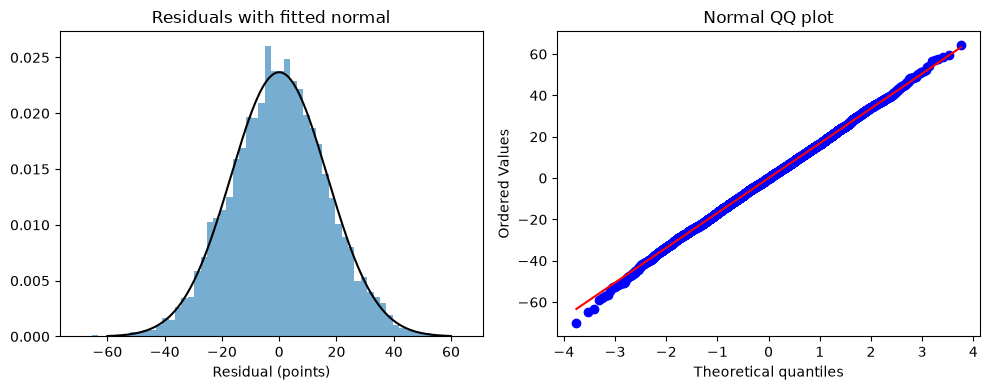

In [2]:
resid = tuning["margin"] - tuning["spread_pred"]
sigma = resid.std()
print(f"mean {resid.mean():.2f}, SD {sigma:.2f}, skew {stats.skew(resid):.2f}, excess kurtosis {stats.kurtosis(resid):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(resid, bins=60, density=True, alpha=0.6)
x = np.linspace(-60, 60, 200)
axes[0].plot(x, stats.norm.pdf(x, resid.mean(), sigma), color="black")
axes[0].set(xlabel="Residual (points)", title="Residuals with fitted normal")
stats.probplot(resid, dist="norm", plot=axes[1])
axes[1].set_title("Normal QQ plot")
plt.tight_layout()

What matters for win probability is the middle of the distribution (does the sign of the margin flip?), not the tails. Fat tails make big blowouts more common than the normal says, but they barely change $P(\text{margin} > 0)$.

## 2. Does sigma change through the season?

Early-season residuals are bigger. The `normal_by_week` version uses a separate sigma for each bucket.

In [3]:
tuning.assign(resid=resid, bucket=evaluate.week_bucket(tuning)).groupby("bucket")["resid"].agg(["std", "size"]).round(2)

,std,size
bucket,,
postseason,17.63,369
weeks 1-4,17.63,2693
weeks 5-8,16.37,2003
weeks 9+,16.34,2936


In [4]:
evaluate.score_probs_by_week(pred, ["ridge_prob_normal", "ridge_prob_normal_by_week", "elo_prob_home"], config.TUNING_SEASONS).round(4)

,games,ridge_prob_normal,ridge_prob_normal_by_week,elo_prob_home,market
bucket,,,,,
weeks 1-4,2612,0.4154,0.4185,0.4383,0.3743
weeks 5-8,2000,0.5437,0.5432,0.5614,0.5216
weeks 9+,2930,0.5246,0.5235,0.5363,0.5094
postseason,369,0.6638,0.6633,0.6706,0.6306
all,7911,0.4999,0.5003,0.5166,0.4736


Separate sigmas don't help. Early-season residuals are bigger mostly because of FCS mismatches, where the win probability is near 1 whatever sigma is. Widening sigma for every September game makes the *close* September games underconfident.

## 3. Cross-check: a free logistic regression

If $\Phi(\text{spread}/\sigma)$ is right, a logit should find intercept ≈ 0 and slope ≈ $1.7/\sigma$ (logit coefficients ≈ 1.7 × probit coefficients).

In [5]:
logit = win_prob.fit_logistic(pred, "spread_pred", config.TUNING_SEASONS)
print(logit.summary().tables[1])
print(f"1.7 / sigma = {1.7 / sigma:.4f}")

                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.0484      0.028      1.707      0.088      -0.007       0.104
spread_pred     0.1006      0.003     40.118      0.000       0.096       0.106
1.7 / sigma = 0.1009


The fitted slope matches $1.7/\sigma$ almost exactly: the spreads are on the right scale. The intercept is about 0.05 (≈ half a point of home edge the spread misses), which is small and not worth a correction.

## 4. Calibration: model vs. Elo vs. market

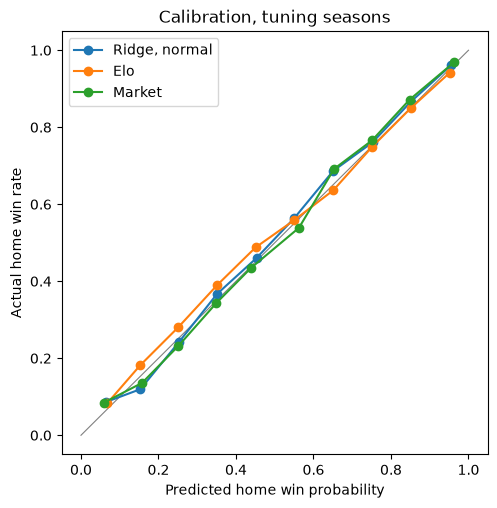

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color="gray", linewidth=0.8)
scored = tuning[tuning["market_spread"].notna()]
for col, label in [("ridge_prob_normal", "Ridge, normal"), ("elo_prob_home", "Elo"), ("market_prob_home", "Market")]:
    bins = pd.cut(scored[col], np.linspace(0, 1, 11), include_lowest=True)
    t = scored.groupby(bins, observed=True).agg(p=(col, "mean"), y=("home_win", "mean"))
    ax.plot(t["p"], t["y"], marker="o", label=label)
ax.set(xlabel="Predicted home win probability", ylabel="Actual home win rate", title="Calibration, tuning seasons")
ax.legend()

In [7]:
rows = {}
for col in ["ridge_prob_normal", "ridge_prob_logistic", "ridge_prob_normal_by_week", "elo_prob_home"]:
    s = evaluate.score_seasons(pred, col, None, config.TUNING_SEASONS).loc["all"]
    rows[col] = {"log_loss": s["model_log_loss"], "brier": s["model_brier"]}
rows["market"] = {"log_loss": s["market_log_loss"], "brier": s["market_brier"]}
pd.DataFrame(rows).T.round(4)

,log_loss,brier
ridge_prob_normal,0.4999,0.1672
ridge_prob_logistic,0.5000,0.1672
ridge_prob_normal_by_week,0.5003,0.1674
elo_prob_home,0.5166,0.1737
market,0.4736,0.1575
